
# PROYECTO FINAL
## Física Computacional I

### Péndulo simple con resistencia del aire

**Estudiante:** Saray Gallego Cañas

**Institución:** Institución Universitaria ITM

**Facultad:** Ciencias Exactas y Aplicadas

**Año:** 2026



# 1. Introducción

El presente proyecto tiene como finalidad analizar el movimiento de un péndulo simple considerando la resistencia del aire como un factor que produce una disminución progresiva de la amplitud de las oscilaciones.

A partir de los datos experimentales proporcionados, se utilizarán herramientas para representar el movimiento, ajustar un modelo matemático y determinar experimentalmente la aceleración gravitacional del lugar donde se encuentra el péndulo.

Además, se estudiará el comportamiento de la energía potencial, cinética y mecánica para comprender cómo se produce la disipación de energía durante el movimiento.



# 2. Carga de los datos experimentales

Para comenzar el análisis, se realiza la lectura del archivo `pendulo_mision.csv`, el cual contiene los datos experimentales del movimiento del péndulo.

El archivo incluye cuatro variables principales: el tiempo (t), el ángulo (θ), la longitud del péndulo (L) y la masa (m).

Se utiliza la biblioteca Pandas para importar y visualizar los datos almacenados en el archivo CSV.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

ruta_archivo = '/content/drive/MyDrive/pendulo_mision.csv'

try:
    pendulo_mision = pd.read_csv(ruta_archivo)
    print("¡Datos cargados con éxito!")
    display(pendulo_mision.head())
except Exception as e:
    print("No se pudo cargar el archivo. Por favor, verifica la ruta de acceso en tu Google Drive.")
    print(f"Error: {e}")

¡Datos cargados con éxito!


,t,theta,L,m
0,0.000,0.1825,0.85,0.15
1,0.151,0.1694,0.85,0.15
2,0.302,0.1469,0.85,0.15
3,0.452,0.1110,0.85,0.15
4,0.603,0.0524,0.85,0.15


In [3]:
import numpy as np
import matplotlib.pyplot as plt

t = pendulo_mision['t'].values
theta = pendulo_mision['theta'].values
L = pendulo_mision['L'].values
m = pendulo_mision['m'].values

print("Datos extraídos correctamente")
print(f"Número de mediciones: {len(t)}")
print(f"Longitud del péndulo: {L[0]} m")
print(f"Masa del péndulo: {m[0]} kg")

Datos extraídos correctamente
Número de mediciones: 200
Longitud del péndulo: 0.85 m
Masa del péndulo: 0.15 kg



# 3. Representación gráfica y estimaciones iniciales

Se realiza una gráfica del ángulo en función del tiempo para observar el comportamiento del péndulo durante sus oscilaciones.

A partir de la inspección visual de la gráfica se estiman dos parámetros importantes:

- Ángulo inicial (θ₀): corresponde al primer máximo de la oscilación.
- Período (T): corresponde al tiempo transcurrido entre dos máximos consecutivos.

Posteriormente, se calcula una estimación inicial de la frecuencia angular mediante la expresión:

$$
\omega \approx \frac{2\pi}{T}
$$


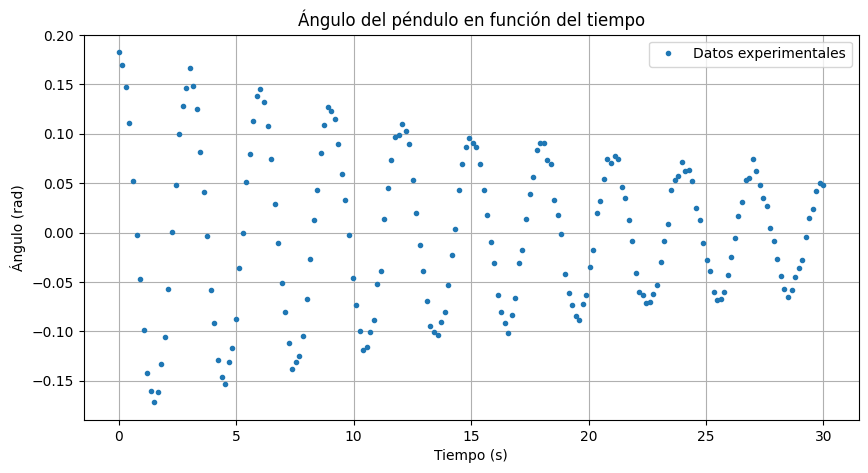

Ángulo inicial estimado: 0.18 rad
Período estimado: 3.0 s
Frecuencia angular estimada: 2.0943951023931953 rad/s


In [4]:
# GRAFICAS PUNTOS EXPERIMENTALES (θ vs. t)


plt.figure(figsize=(10, 5))

plt.plot(t, theta, 'o', markersize=3, label='Datos experimentales')

plt.xlabel('Tiempo (s)')
plt.ylabel('Ángulo (rad)')
plt.title('Ángulo del péndulo en función del tiempo')
plt.grid()
plt.legend()

plt.show()


theta0_estimado = 0.18
T_estimado = 3.0

omega_estimado = 2 * np.pi / T_estimado

print("Ángulo inicial estimado:", theta0_estimado, "rad")
print("Período estimado:", T_estimado, "s")
print("Frecuencia angular estimada:", omega_estimado, "rad/s")



### Análisis de los resultados

La gráfica permite observar un movimiento oscilatorio cuya amplitud disminuye progresivamente con el tiempo. Este comportamiento se debe a la resistencia del aire, que produce un amortiguamiento en el movimiento.

A partir de la gráfica se obtienen las estimaciones iniciales del ángulo, el período y la frecuencia angular, que serán utilizadas posteriormente para realizar el ajuste matemático.



# 4. Ajuste del modelo matemático

Para describir el movimiento del péndulo se utiliza el modelo matemático de un oscilador amortiguado:

$$
\theta(t)=\theta_0 e^{-\gamma t}\cos(\omega t)
$$

Donde:

- θ₀ representa el ángulo inicial.
- γ representa el coeficiente de amortiguamiento.
- ω representa la frecuencia angular amortiguada.
- t representa el tiempo.

Se utiliza la función `curve_fit` de la biblioteca SciPy para ajustar el modelo a los datos experimentales y encontrar los valores óptimos de los parámetros.


In [5]:
from scipy.optimize import curve_fit

# Definir la función del modelo
def modelo(t, theta0, gamma, omega):
    return theta0 * np.exp(-gamma*t) * np.cos(omega*t)

# Estimaciones iniciales
p0 = [theta0_estimado, 0.05, omega_estimado]

# Realizar el ajuste
parametros, covarianza = curve_fit(modelo, t, theta, p0=p0)

# Extraer los parámetros óptimos
theta0_opt, gamma_opt, omega_opt = parametros

print("Parámetros óptimos:")
print("Ángulo inicial:", theta0_opt, "rad")
print("Amortiguamiento:", gamma_opt, "s^-1")
print("Frecuencia angular:", omega_opt, "rad/s")

Parámetros óptimos:
Ángulo inicial: 0.1793425988489842 rad
Amortiguamiento: 0.03966631024791709 s^-1
Frecuencia angular: 2.0914786171738804 rad/s



# 5. Incertidumbres de los parámetros

Después de realizar el ajuste matemático, se calculan las incertidumbres asociadas a los parámetros obtenidos.

Para ello, se utiliza la matriz de covarianza proporcionada por `curve_fit`. Las incertidumbres se calculan mediante la raíz cuadrada de los elementos de su diagonal:

$$
\sigma_i=\sqrt{Cov_{ii}}
$$

Este procedimiento permite expresar los valores ajustados acompañados de sus respectivas incertidumbres, proporcionando información sobre la precisión de los parámetros estimados.


In [6]:
# Calcular las incertidumbres
incertidumbres = np.sqrt(np.diag(covarianza))

dtheta0, dgamma, domega = incertidumbres

print("Incertidumbres de los parámetros:")
print("Incertidumbre de theta0:", dtheta0, "rad")
print("Incertidumbre de gamma:", dgamma, "s^-1")
print("Incertidumbre de omega:", domega, "rad/s")

Incertidumbres de los parámetros:
Incertidumbre de theta0: 0.0011966901741341481 rad
Incertidumbre de gamma: 0.0005494289537076517 s^-1
Incertidumbre de omega: 0.0003468305747168273 rad/s



# 6. Determinación de la aceleración gravitacional

Con los parámetros obtenidos mediante el ajuste matemático, se calcula la aceleración gravitacional experimental utilizando la ecuación:

$$
g_{exp}=L(\omega^2+\gamma^2)
$$

Posteriormente, se compara el resultado con los valores nominales de aceleración gravitacional proporcionados en la tabla del proyecto.

Para determinar el destino de la sonda se calcula el porcentaje de error relativo:

$$
\%Error=
\frac{|g_{exp}-g_{nominal}|}{g_{nominal}}\times100
$$

El cuerpo celeste que presente el menor error relativo será considerado el destino más probable de la misión.


In [7]:
# Obtener los valores constantes de longitud y masa
L0 = L[0]
m0 = m[0]

# Calcular la gravedad experimental
g_exp = L0 * (omega_opt**2 + gamma_opt**2)

print("Gravedad experimental:", g_exp, "m/s^2")

Gravedad experimental: 3.7194777889246136 m/s^2


In [8]:
# Valores nominales de gravedad
destinos = {
    "Luna terrestre": 1.62,
    "Marte": 3.72,
    "Mercurio": 3.70,
    "Titán": 1.35,
    "Venus": 8.87,
    "Tierra (Medellín)": 9.78,
    "Próxima Centauri b": 10.70
}

# Calcular el error relativo para cada destino
for planeta, g_nominal in destinos.items():

    error = abs(g_exp - g_nominal) / g_nominal * 100

    print(f"{planeta}: {error:.5f} %")

# Identificar el destino con menor error
destino = min(destinos, key=lambda x: abs(g_exp - destinos[x]))

print("\nEl destino identificado es:", destino)

Luna terrestre: 129.59739 %
Marte: 0.01404 %
Mercurio: 0.52643 %
Titán: 175.51687 %
Venus: 58.06677 %
Tierra (Medellín): 61.96853 %
Próxima Centauri b: 65.23853 %

El destino identificado es: Marte



# 7. Ajuste del modelo y envolventes de amplitud

Se realiza una gráfica comparativa que contiene los datos experimentales y la curva continua obtenida mediante el ajuste matemático.

También se representan las envolventes superior e inferior de la amplitud, definidas por:

$$
\theta_{env}(t)=\pm\theta_0e^{-\gamma t}
$$

Estas curvas permiten observar cómo disminuye la amplitud de las oscilaciones debido al amortiguamiento producido por la resistencia del aire.


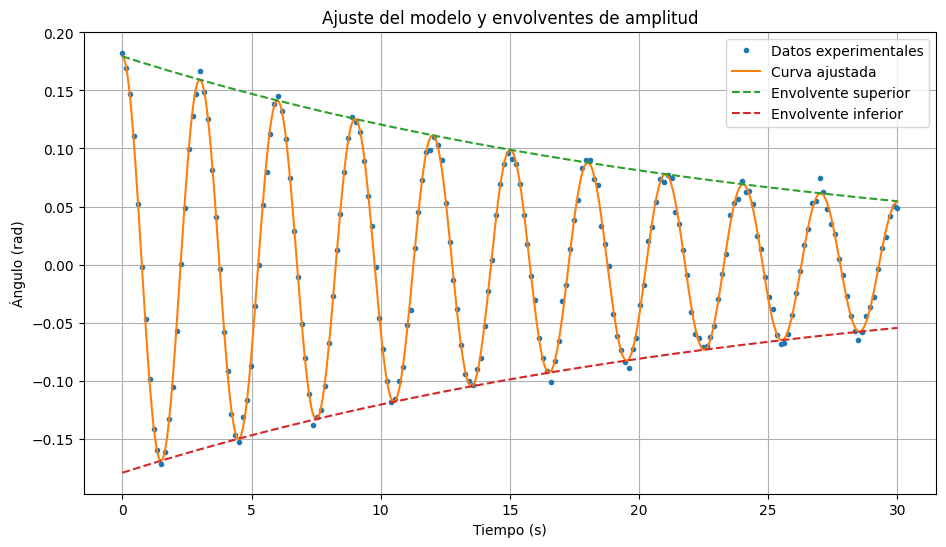

In [9]:
# Crear un intervalo de tiempo para la curva continua
t_ajuste = np.linspace(min(t), max(t), 1000)

# Evaluar el modelo ajustado
theta_ajustada = modelo(t_ajuste, theta0_opt, gamma_opt, omega_opt)

# Calcular las envolventes
envolvente_superior = theta0_opt * np.exp(-gamma_opt*t_ajuste)
envolvente_inferior = -theta0_opt * np.exp(-gamma_opt*t_ajuste)

# Graficar
plt.figure(figsize=(11, 6))

plt.plot(t, theta, 'o', markersize=3, label='Datos experimentales')
plt.plot(t_ajuste, theta_ajustada, label='Curva ajustada')
plt.plot(t_ajuste, envolvente_superior, '--', label='Envolvente superior')
plt.plot(t_ajuste, envolvente_inferior, '--', label='Envolvente inferior')

plt.xlabel('Tiempo (s)')
plt.ylabel('Ángulo (rad)')
plt.title('Ajuste del modelo y envolventes de amplitud')
plt.grid()
plt.legend()

plt.show()


# 8. Evolución y disipación de la energía mecánica

En esta actividad se analiza el comportamiento energético del péndulo durante su movimiento.

Inicialmente, se calcula la velocidad angular experimental mediante diferenciación numérica utilizando la función `np.gradient()`.

Posteriormente, se calculan las siguientes magnitudes:

**Energía potencial gravitatoria:**

$$
U(t)=mg_{exp}L(1-\cos\theta)
$$

**Energía cinética:**

$$
K(t)=\frac{1}{2}mL^2\dot{\theta}^{\,2}
$$

**Energía mecánica total:**

$$
E(t)=K(t)+U(t)
$$

Finalmente, se representan las tres energías en una misma gráfica para estudiar su evolución e interpretar la disipación de energía causada por la resistencia del aire.


In [10]:
theta_punto = np.gradient(theta, t)
print("Velocidad angular calculada correctamente.")

U = m0 * g_exp * L0 * (1 - np.cos(theta))
print("Energía potencial calculada correctamente.")


K = 0.5 * m0 * L0**2 * theta_punto**2
print("Energía cinética calculada correctamente.")


E = K + U
print("Energía mecánica calculada correctamente.")

Velocidad angular calculada correctamente.
Energía potencial calculada correctamente.
Energía cinética calculada correctamente.
Energía mecánica calculada correctamente.


In [11]:
# Valores inicial y final de la energía mecánica
E_inicial = E[0]
E_final = E[-1]

# Porcentaje de disminución de energía
disminucion = ((E_inicial - E_final) / E_inicial) * 100

print("Energía mecánica inicial:", E_inicial, "J")
print("Energía mecánica final:", E_final, "J")
print("Disminución de energía:", disminucion, "%")

Energía mecánica inicial: 0.008283411239040141 J
Energía mecánica final: 0.0005656315671303089 J
Disminución de energía: 93.17151411649759 %


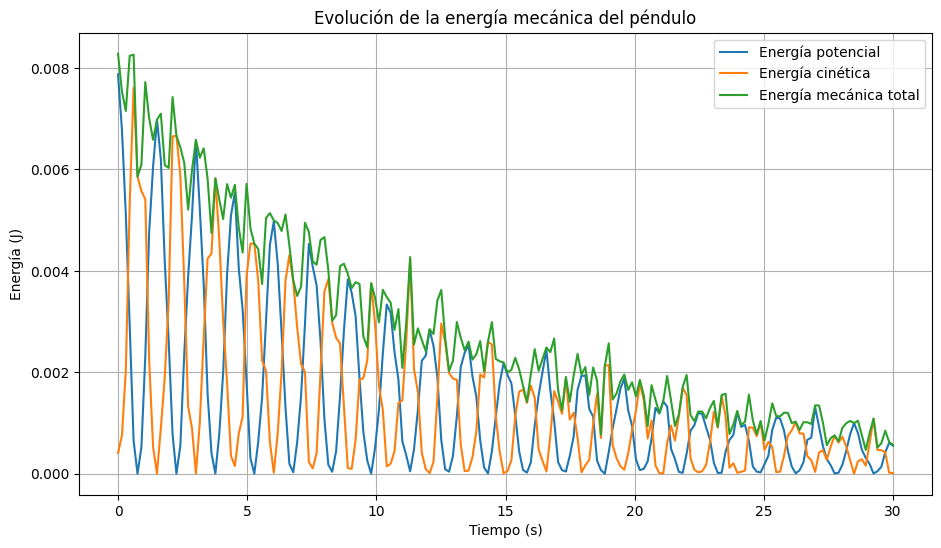

In [12]:
plt.figure(figsize=(11, 6))

plt.plot(t, U, label='Energía potencial')
plt.plot(t, K, label='Energía cinética')
plt.plot(t, E, label='Energía mecánica total')

plt.xlabel('Tiempo (s)')
plt.ylabel('Energía (J)')
plt.title('Evolución de la energía mecánica del péndulo')
plt.grid()
plt.legend()

plt.show()


### Análisis del comportamiento energético

Durante el movimiento del péndulo se produce un intercambio continuo entre la energía potencial y la energía cinética. Cuando el péndulo alcanza sus posiciones extremas, la energía potencial es mayor y la energía cinética disminuye. Por el contrario, al pasar por la posición de equilibrio, la energía cinética aumenta.

Sin embargo, debido a la resistencia del aire, la energía mecánica total disminuye progresivamente. Esto ocurre porque parte de la energía mecánica se transforma en otras formas de energía, principalmente energía térmica, como consecuencia del rozamiento.



# 9. Conclusiones

A partir del análisis computacional del péndulo simple con resistencia del aire, fue posible estudiar el comportamiento de un movimiento oscilatorio amortiguado mediante datos experimentales y herramientas de programación.

El ajuste matemático permitió determinar los parámetros del movimiento y calcular experimentalmente la aceleración gravitacional, lo que hizo posible identificar el cuerpo celeste correspondiente mediante la comparación con los valores de referencia.

Asimismo, el análisis energético permitió observar el intercambio entre la energía potencial y cinética, así como la disminución progresiva de la energía mecánica debido a la resistencia del aire.

